In [ ]:
% pip install pandas
% pip install numpy
% pip install matplotlib
% pip install scikit-learn
% pip install progress
% pip install scikit-bio
 
% git clone https://github.com/aleixalcacer/archetypes
% pip install "archetypes/"

In [5]:
import pandas as pd
import numpy as np
from tqdm import tqdm
import time
import sklearn
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import os

from archetypes import AA
from archetypes.visualization import stacked_bar, simplex
from archetypes.datasets import sort_by_archetype_similarity, permute_dataset
import json

## Performing AA

In [40]:
dataDir = os.path.join("datasets", "tsv")
outDir = r"results"

otuFile = "hadza_otu_nov.tsv"
taxFile = "hadza_tax_nov.tsv"

otu = pd.read_table(os.path.join(dataDir, otuFile), index_col=0)
tax = pd.read_table(os.path.join(dataDir, taxFile), index_col=0)

In [41]:
FRAC = 0.1
otu_sample = otu.sample(frac=FRAC)

In [42]:
# ------tax_glom() equivalent------

group = "Genus" # Change this to "Kingdom", "Phylum", "Class", "Order", "Family", "Genus",to group by that taxonomic level

# No of uniques => {Kingdom: 1, Phylum: 15, Class: 25, Order: 44, Family: 77, Genus: 305}

grouped_cols = tax[group].unique()

otu_grouped = pd.DataFrame(index=otu_sample.index, columns=grouped_cols)

i = 0
for c in tqdm(otu_sample.columns):
    grp_col = tax[group][c]
    
    if(pd.isnull(otu_grouped[grp_col]).all()):
        otu_grouped[grp_col] = otu_sample[c]
        continue

    otu_grouped[grp_col] = otu_grouped[grp_col] + otu_sample[c]
    # print(f"Processed column ({i+1}/{len(otu.columns)}): {grp_col}")

    i += 1

otu_grouped.columns = otu_grouped.columns.astype(str)


  0%|          | 0/2647 [00:00<?, ?it/s]

100%|██████████| 2647/2647 [00:00<00:00, 3831.78it/s]


In [43]:
otu_log = otu_grouped.copy()
otu_log = otu_log.map(lambda x: np.log2(x+1))

In [44]:
import scipy.spatial
from skbio.tree import TreeNode
from skbio.diversity import beta_diversity
from skbio.stats.ordination import pcoa
import scipy

# metadata = pd.read_table('metadata.tsv', index_col=0)
pcoa_data = otu_log.copy()

method = 'braycurtis' #scipy.spatial.distance.jensenshannon  #'jensenshannon' or 'bray_curtis', unifrac is problematic
bdiv = beta_diversity(
    method, pcoa_data, ids=pcoa_data.index, pairwise_func=scipy.spatial.distance.pdist
)
# Perform PCoA
pcoa_results = pcoa(bdiv, number_of_dimensions=2)

# Extract the coordinates
pcoa_coordinates = pcoa_results.samples

c:\Users\rayve\.conda\envs\GHG_Work\Lib\site-packages\skbio\stats\ordination\_principal_coordinate_analysis.py:146: RuntimeWarning: The result contains negative eigenvalues. Please compare their magnitude with the magnitude of some of the largest positive eigenvalues. If the negative ones are smaller, it's probably safe to ignore them, but if they are large in magnitude, the results won't be useful. See the Notes section for more details. The smallest eigenvalue is -1.5822452337207045 and the largest is 97.7103243340286.
  warn(


C:\Users\rayve\AppData\Local\Temp\ipykernel_28536\1046707342.py:8: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  plt.xlabel(f"PC1 ({pcoa_results.proportion_explained[0]:.2%} variance explained)")
C:\Users\rayve\AppData\Local\Temp\ipykernel_28536\1046707342.py:9: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  plt.ylabel(f"PC2 ({pcoa_results.proportion_explained[1]:.2%} variance explained)")


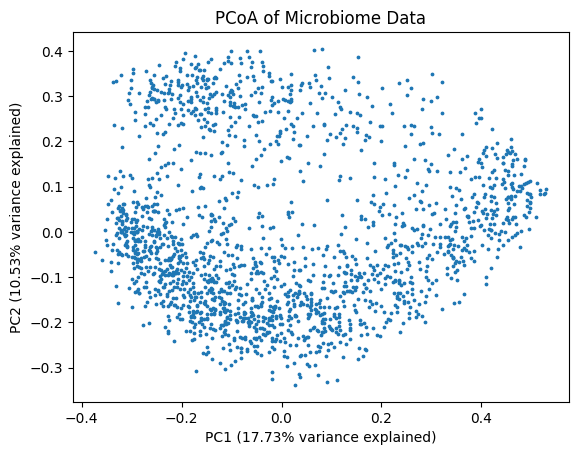

In [45]:
import matplotlib.pyplot as plt

# Create a scatter plot

plt.scatter(pcoa_coordinates['PC1'], pcoa_coordinates['PC2'], s=3)

# Add labels and title
plt.xlabel(f"PC1 ({pcoa_results.proportion_explained[0]:.2%} variance explained)")
plt.ylabel(f"PC2 ({pcoa_results.proportion_explained[1]:.2%} variance explained)")
plt.title("PCoA of Microbiome Data")

# # Add sample labels if desired
# for idx, row in pcoa_coordinates.iterrows():
#     plt.annotate(idx, (row['PC1'], row['PC2']))

plt.show()



In [46]:
# from archetypes.numpy._aa_3 import AA_3
from archetypes import AA

col1, col2 = "PC1", "PC2"

AA_data = pcoa_coordinates[[col1, col2]].to_numpy()

method_kwargs = {
    "max_iter_optimizer": 10,
}

N_ARCHETYPES = 3
aa = AA(n_archetypes=N_ARCHETYPES, method="pgd", method_kwargs=method_kwargs, random_state=3)


aa.fit(AA_data)

print(aa.archetypes_)

[[-0.32173778  0.34726429]
 [-0.17125383 -0.30685565]
 [ 0.53006443  0.09562667]]


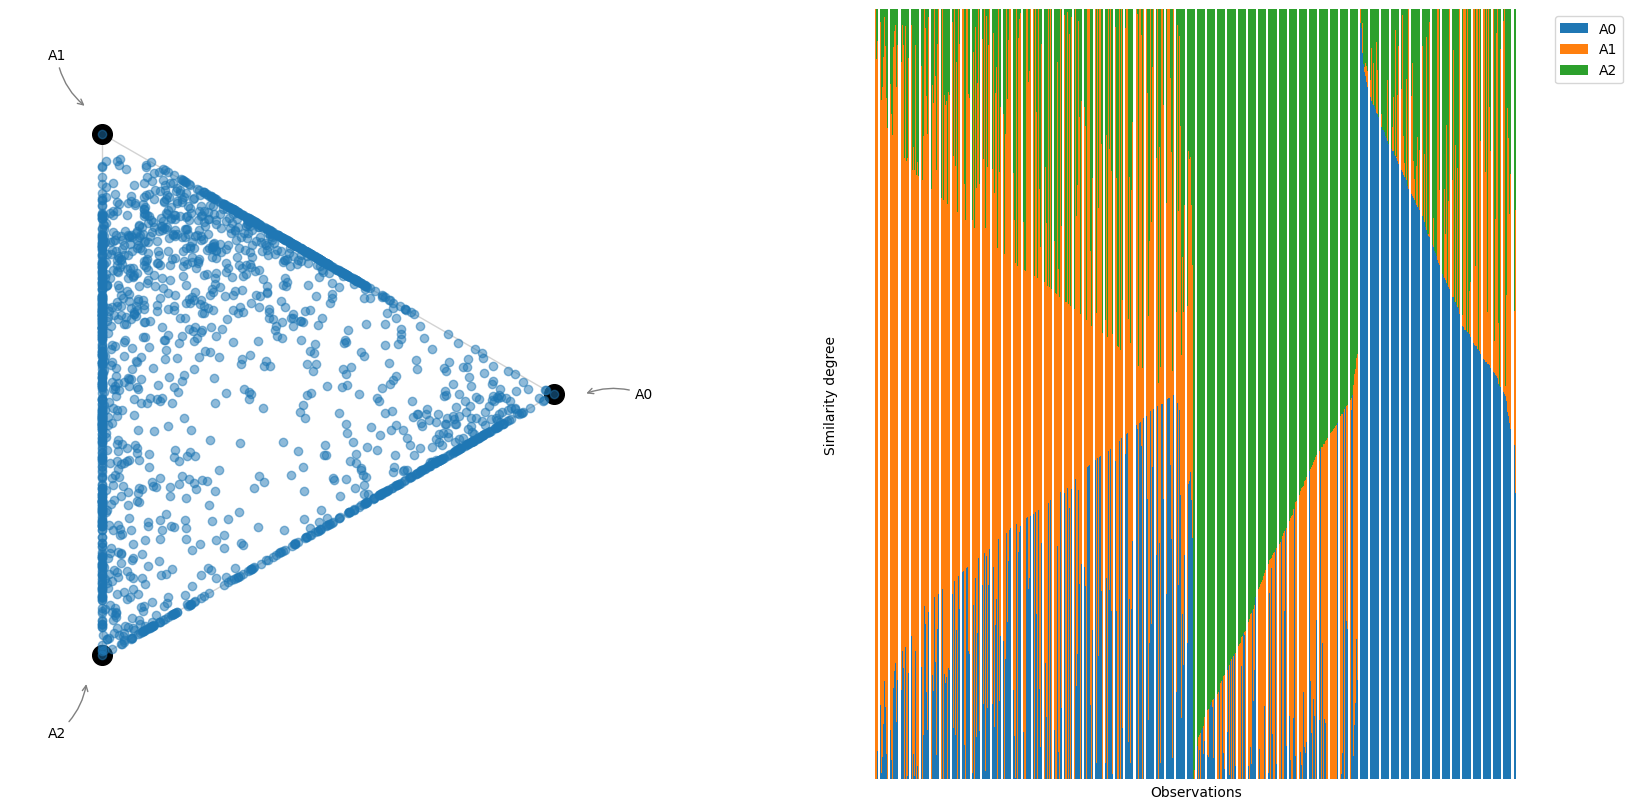

In [47]:
data_sorted, info = sort_by_archetype_similarity(AA_data, [aa.similarity_degree_], aa.archetypes_)

similarity_degree_permuted, _ = permute_dataset(aa.similarity_degree_, info["perms"])

fig, ax = plt.subplots(1, 2, figsize=(20, 10))
simplex(aa.similarity_degree_, alpha=0.5, ax=ax[0], show_vertices=True)
stacked_bar(similarity_degree_permuted, ax=ax[1])

plt.show()


C:\Users\rayve\AppData\Local\Temp\ipykernel_28536\254064229.py:4: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  plt.xlabel(f"PC1 ({pcoa_results.proportion_explained[0]:.2%} variance explained)")
C:\Users\rayve\AppData\Local\Temp\ipykernel_28536\254064229.py:5: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  plt.ylabel(f"PC2 ({pcoa_results.proportion_explained[1]:.2%} variance explained)")


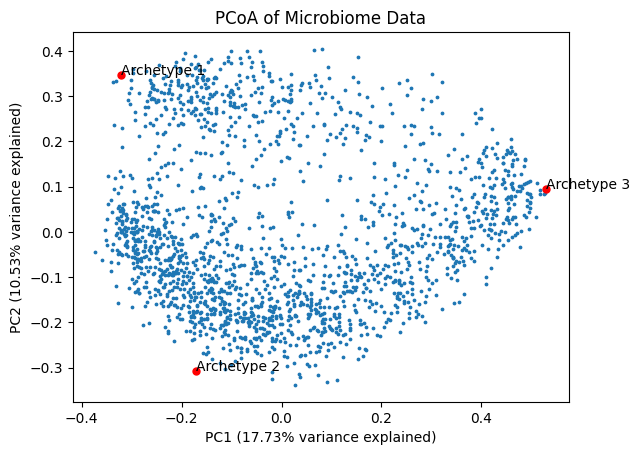

In [48]:
plt.scatter(pcoa_coordinates['PC1'], pcoa_coordinates['PC2'], s=3)

# Add labels and title
plt.xlabel(f"PC1 ({pcoa_results.proportion_explained[0]:.2%} variance explained)")
plt.ylabel(f"PC2 ({pcoa_results.proportion_explained[1]:.2%} variance explained)")
plt.title("PCoA of Microbiome Data")

plt.scatter(aa.archetypes_[:, 0], aa.archetypes_[:, 1], c="red", s=25)
for i, arch in enumerate(aa.archetypes_):
    plt.text(arch[0], arch[1], f"Archetype {i+1}")

# Closest Points to Archetypes
# for i, arch in enumerate(aa.archetypes_):
#     idx = np.argmax(aa.similarity_degree_[:, i])
#     plt.scatter(pcoa_coordinates.iloc[idx]['PC1'], pcoa_coordinates.iloc[idx]['PC2'], c="black", s=25)

plt.show()

In [53]:
otu_aa = pd.DataFrame(aa.similarity_degree_, index=pcoa_coordinates.index, columns=[f"Archetype {i+1}" for i in range(N_ARCHETYPES)])

# Make a json file containing all details for the archetypes
import json
aa_dict = {
    "archetypes": aa.archetypes_.tolist(),
    "similarity_degree": aa.similarity_degree_.tolist(),
    "labels": aa.labels_.tolist(), 
    "index": pcoa_coordinates.index.tolist(),
    "columns": [f"Archetype {i+1}" for i in range(N_ARCHETYPES)], 
    "loss": aa.loss_,
}


In [54]:
methodName = method if isinstance(method, str) else "jensenshannon"

outName = f"otu_AA_{FRAC}_{group}_{methodName}.json"
outPath = os.path.join(outDir, outName)

json.dump(aa_dict, open(outPath, "w"))
# otu_aa.to_csv(outPath, sep="\t")

# Analysis

In [ ]:
dataDir = "datasets/tsv"

fName = "results\SBATCH_N3_N12\otu_AA_K11_1.0_Genus_braycurtis.json" # if outPath is None else outPath
otu_dict = json.load(open(fName, "r"))
otu_aa = pd.DataFrame(otu_dict["similarity_degree"], index=otu_dict["index"], columns=otu_dict["columns"])
aa_labels = np.array(otu_dict["labels"])
aa_archetypes = otu_dict["archetypes"]

samPath = os.path.join(dataDir, "hadza_sam_nov.tsv")

# Create hadza_sam dataframe with index column as SampleID2
hadza_sam = pd.read_table(samPath, index_col=0)

C:\Users\rayve\AppData\Local\Temp\ipykernel_15372\1779524809.py:12: DtypeWarning: Columns (1,3,4,5,6,7,9,10,11,12,13,14,15,16,17,18,19,20,22,24,25,26,27,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,57,58,61,65,66,67,68,69,70,71,72,73,75,76,77,78,79,80,81,82,83,86,87,88,89,90,91,92,95,97,98,100,101,102,103,105,112,113,114,116,118,120,123,134,135,136,137,138,139,140,141,142,143,146,147,148,149,150,154,155,156,159,161,162,165,166,167,168,169,170,171,172,173,174,175,176,177,178,179,180,181,182,183,184,185,186,187,188,189,190,191,192,194,197,198) have mixed types. Specify dtype option on import or set low_memory=False.
  hadza_sam = pd.read_table(samPath, index_col=0)


In [106]:
# For indexes in hadza_sam that are nan, replace with SampleID2
newIndex = hadza_sam.index
newIndex = newIndex.where(newIndex.notnull(), hadza_sam["SampleID2"])

hadza_sam.index = newIndex

C:\Users\rayve\AppData\Local\Temp\ipykernel_15372\3940265023.py:6: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap("tab20", n_archs)


<Axes: >

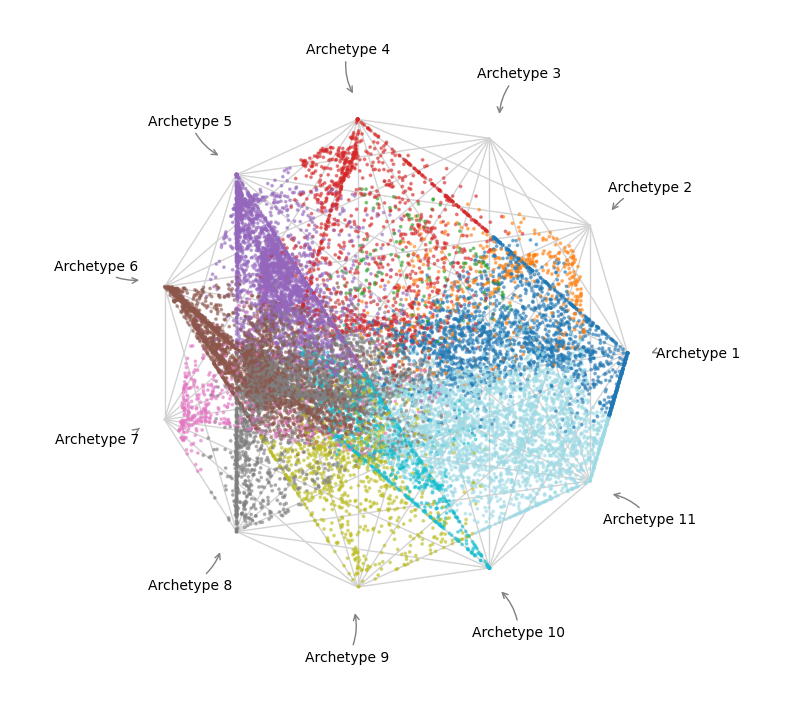

In [100]:
n_archs = len(aa_archetypes)
# Normalize the aa_labels

color =  aa_labels

cmap = plt.cm.get_cmap("tab20", n_archs)

fig, ax = plt.subplots(1, 1, figsize=(10, 10))
simplex(otu_aa.to_numpy(), alpha=0.5, ax=ax, c=color, cmap=cmap, s=3, vertices_labels=otu_aa.columns)


In [107]:
arch_idx = [np.argmax(otu_aa[arch]) for arch in otu_aa.columns]
print(arch_idx)

arch_ID = [hadza_sam.index[i] for i in arch_idx]
print(f"Closest Archetypes: {arch_ID}")



[2230, 8006, 367, 915, 1664, 12808, 2112, 910, 7122, 3278, 12667]
Closest Archetypes: ['Bgsng7178.m51', 'SRR7570685', 'Bgsng7192.m35', 'Bgsng7155.m20', 'PE1C0335.m5.91', 'SRR7576626', 'Bgsng7128.m50', 'Bgsng7155.m16', '416.Family3135.Child1.30M', 'BR1C0232.m2', 'SRR7576447']


In [117]:
summary_cols = ["age_months", "location", "GENDER"]  # Dataset Specific
summary = hadza_sam.loc[arch_ID, summary_cols]

# Print the summary along with serial numbers
summary.insert(0, "Archetype #", range(1, 1 + len(summary)))

print(summary)

                           Archetype #  age_months    location GENDER
SampleID                                                             
Bgsng7178.m51                        1   50.400000  Bangladesh      2
SRR7570685                           2    4.041068  Washington    NaN
Bgsng7192.m35                        3   34.100000  Bangladesh      2
Bgsng7155.m20                        4   19.000000  Bangladesh      2
PE1C0335.m5.91                       5    5.900000        Peru      1
SRR7576626                           6   13.273101      Sweden    NaN
Bgsng7128.m50                        7   49.000000  Bangladesh      2
Bgsng7155.m16                        8   15.100000  Bangladesh      2
416.Family3135.Child1.30M            9   30.000000      Malawi    NaN
BR1C0232.m2                         10    2.000000      Brazil      1
SRR7576447                          11   31.671458     Finland    NaN


Dropped 1261 data points: Index not found in metadata


C:\Users\rayve\AppData\Local\Temp\ipykernel_15372\606014140.py:38: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap(cmap_name, len(unique_colors))


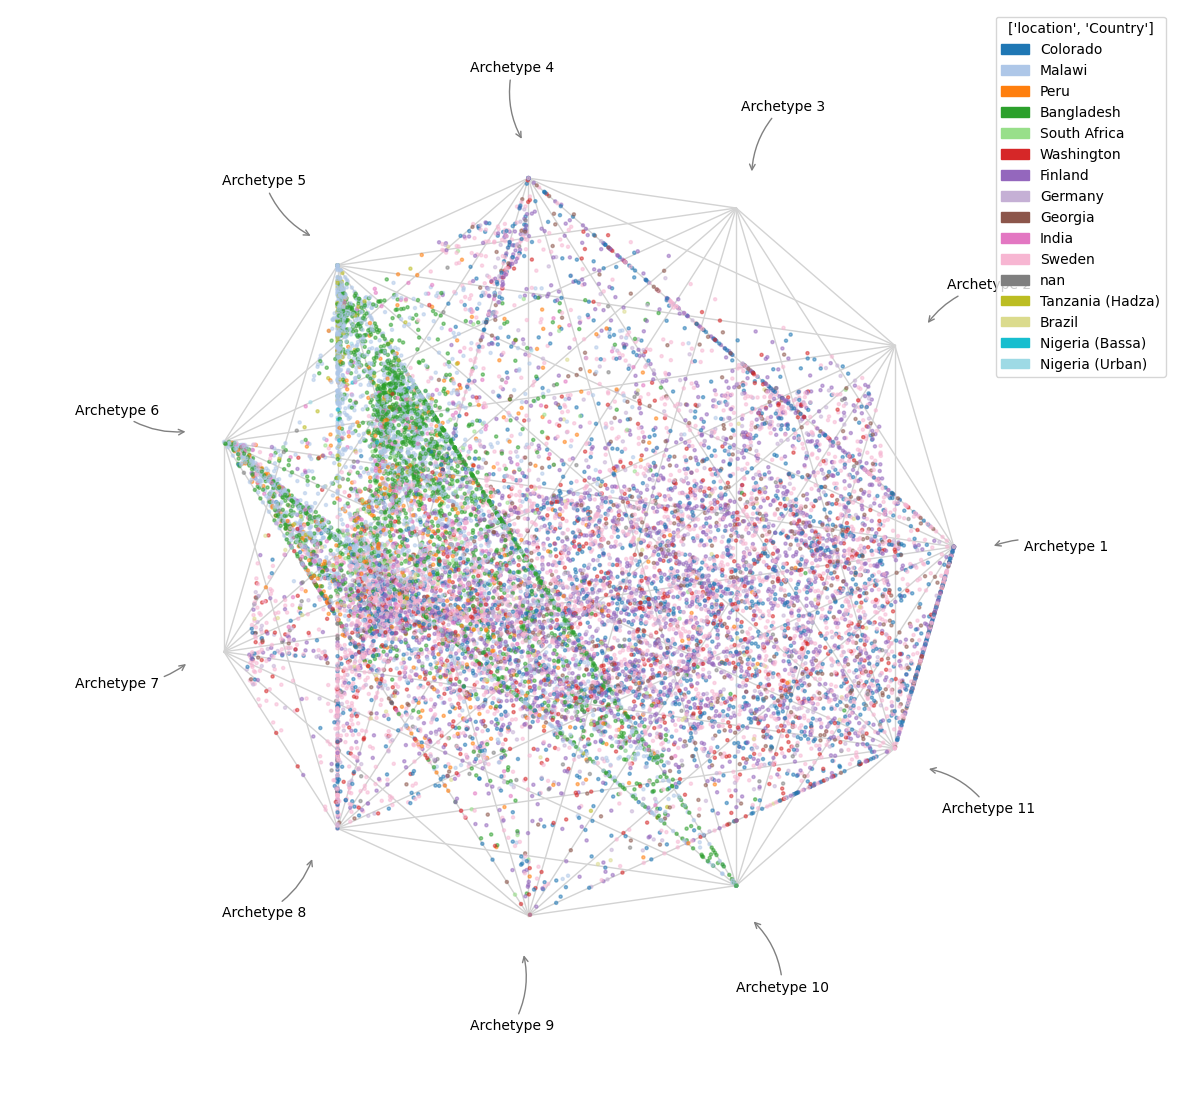

In [ ]:
from matplotlib.patches import Patch
import matplotlib.cm as cm


def filter_further(data, further_filter, filter_type): 
    if filter_type == "equals": 
        return data[data.isin(further_filter)]
    elif filter_type == "not_equals":
        return data[~data.isin(further_filter)]
    elif filter_type == "greater_than":
        return data[data > further_filter]
    elif filter_type == "less_than":
        return data[data < further_filter]


def plot_simplex(otu_aa, hadza_sam, filter_cols, 
                cmap_name="tab20", legend_type="discrete", 
                remove_nan=False, further_filter=None, figsize=(15, 15)):
    """ 
    otu_aa: DataFrame
        The archetypal analysis data
    hadza_sam: DataFrame
        The metadata
    filter_cols: list
        The columns to filter the data by (must contain exact column names from metadata)
    cmap_name: str (optional)
        The name of the colormap to use
    legend_type: str (optional)
        The type of legend to use. Can be "discrete" or "continuous"
    remove_nan: bool (optional)
        Whether to remove NaN values from the data
    further_filter: Dict (optional) = {"filter_type": "equals", "value": []}
        Further filter the data by the values in this list
    figsize: tuple (optional)
        The size of the figure
    """

    present_idx = otu_aa.index.intersection(hadza_sam.index)
    present_points = otu_aa.loc[present_idx]

    # Print the number of values dropped
    print(f"Dropped {len(otu_aa) - len(present_points)} data points: Index not found in metadata")

    # For each data point, add the first non-null value from filter_cols to the filter_labels
    filter_labels = pd.Series(index=present_points.index, dtype=str)
    for col in filter_cols:
        filter_labels = filter_labels.fillna(hadza_sam.loc[present_idx, col])

    # If further_filter is not none, filter the dataset by matching values to each further_filter element
    if further_filter is not None:
        present_points = filter_further(present_points, further_filter["filter_type"], further_filter["value"])
        filter_labels = filter_further(filter_labels, further_filter["filter_type"], further_filter["value"])

    if remove_nan:
        nan_idx = filter_labels.index[filter_labels.isnull()]
        present_points = present_points.drop(nan_idx)
        filter_labels = filter_labels.drop(nan_idx)

    if(legend_type == "discrete"):
        unique_colors = {c: i for i, c in enumerate(filter_labels.unique())}
        color = filter_labels.map(unique_colors)

    elif(legend_type == "continuous"):
        unique_colors = filter_labels
        color = filter_labels.astype(float)

    cmap = plt.cm.get_cmap(cmap_name, len(unique_colors))
    fig, ax = plt.subplots(1, 1, figsize=figsize)
    simplex(present_points, alpha=0.5, ax=ax, c=color, cmap = cmap, s=5, vertices_labels=otu_aa.columns)

    def add_discrete_legend(ax, unique_colors, cmap):
        legend_patches = [
            Patch(color=cmap(unique_colors[c]), label=c)
            for c in unique_colors
        ]

        # Add the legend to the plot
        ax.legend(handles=legend_patches, title=filter_cols, loc='upper right')

    def add_continuous_legend(ax, filter_labels, cmap):
        # Add the legend to the plot with appropriate min and max values
        cbar = plt.colorbar(cm.ScalarMappable(cmap=cmap), ax=ax, orientation='vertical')
        cbar.set_label(f"{filter_cols}: min: {str(min(filter_labels))}; max: {str(max(filter_labels))}" )

    if legend_type == "discrete":
        add_discrete_legend(ax, unique_colors, cmap)
    elif legend_type == "continuous":
        add_continuous_legend(ax, filter_labels, cmap)


plot_simplex(otu_aa, hadza_sam, ["location", "Country"])


Dropped 1261 data points: Index not found in metadata


C:\Users\rayve\AppData\Local\Temp\ipykernel_15372\606014140.py:38: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap(cmap_name, len(unique_colors))


IndexError: tuple index out of range

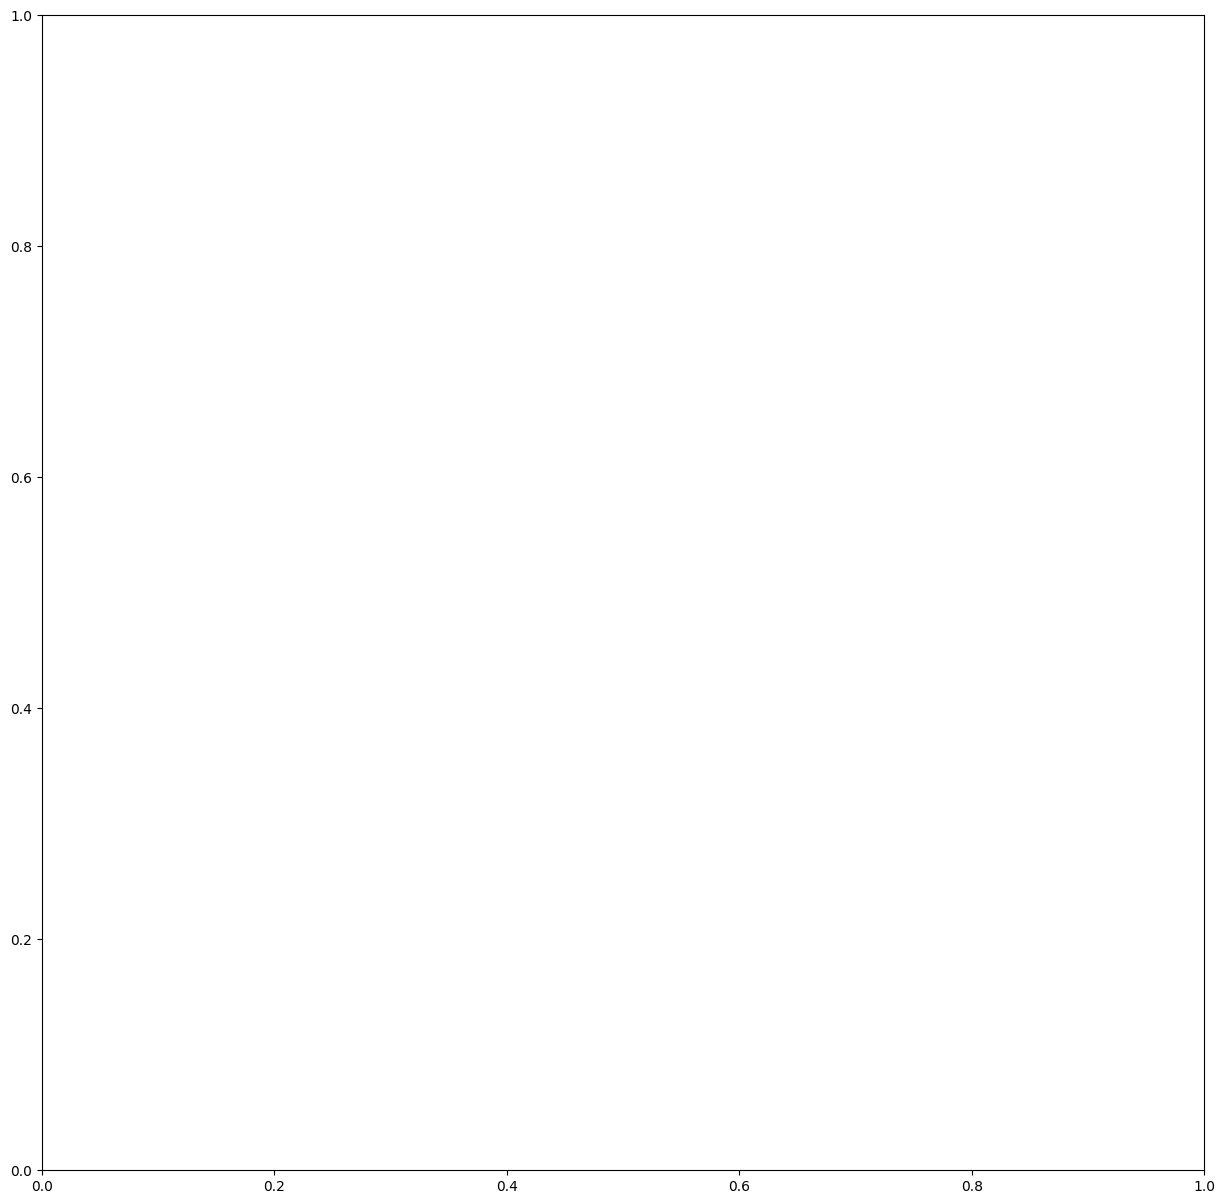

In [ ]:
# FOR COUNTRY
filter_cols = ["location", "Country"]
otu_aa_swapped = otu_aa[["Archetype 1", "Archetype 4", "Archetype 8", "Archetype 5", "Archetype 10","Archetype 6", "Archetype 9", "Archetype 11", "Archetype 2", "Archetype 3", "Archetype 7"]]

plot_simplex(otu_aa_swapped, hadza_sam, filter_cols, cmap_name="tab20", legend_type="discrete", remove_nan=True)

Dropped 1261 data points: Index not found in metadata


C:\Users\rayve\AppData\Local\Temp\ipykernel_15372\1618605518.py:18: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  filter_labels = filter_labels.fillna(hadza_sam.loc[present_idx, col])
C:\Users\rayve\AppData\Local\Temp\ipykernel_15372\1618605518.py:38: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap(cmap_name, len(unique_colors))


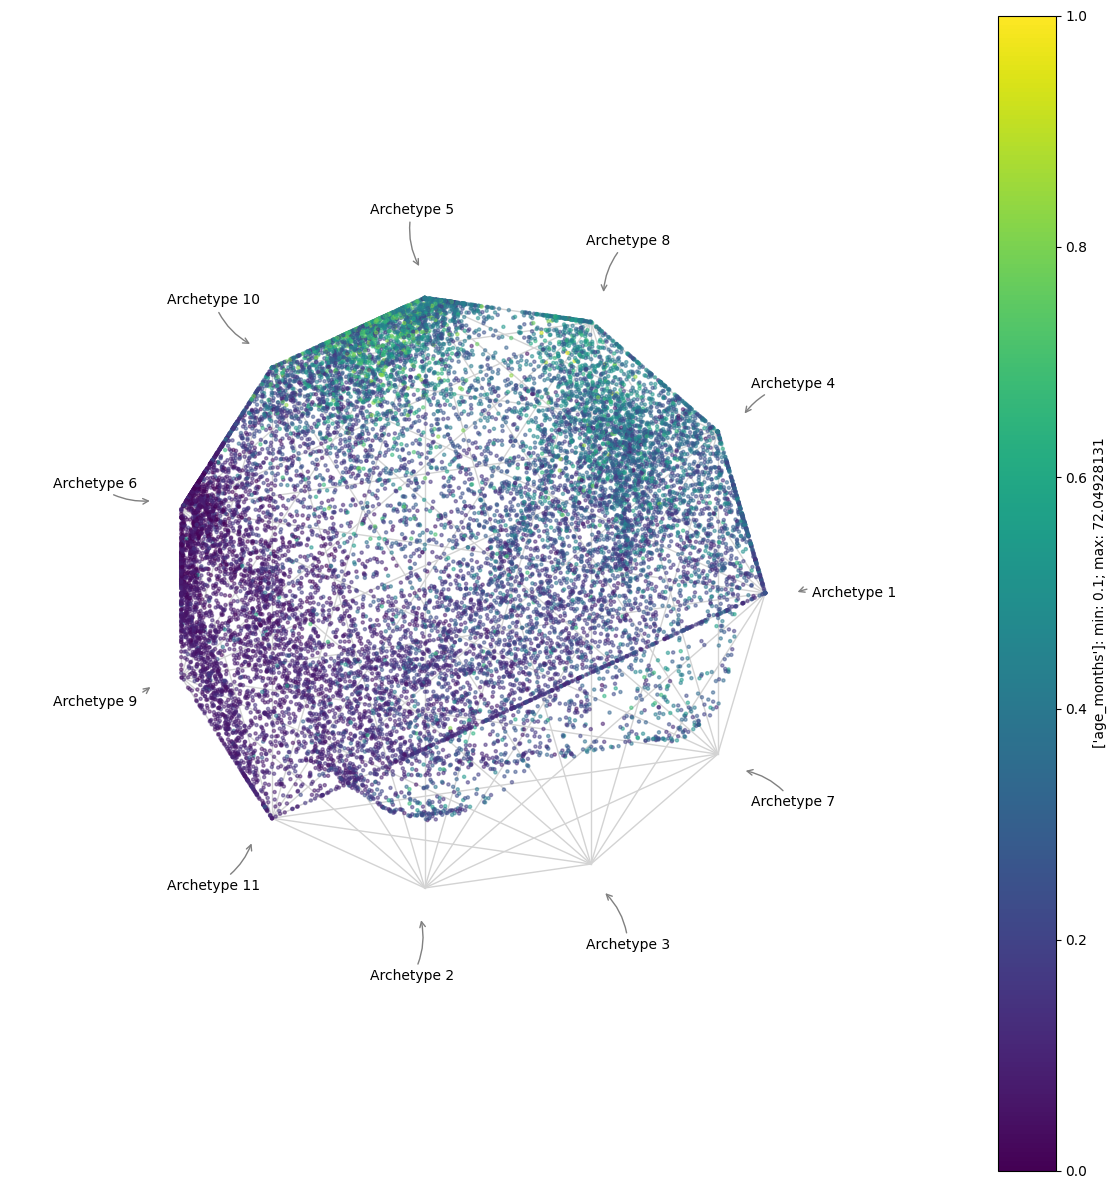

In [124]:
# FOR AGE

# Swapping columns
otu_aa_swapped = otu_aa[["Archetype 1", "Archetype 4", "Archetype 8", "Archetype 5", "Archetype 10","Archetype 6", "Archetype 9", "Archetype 11", "Archetype 2", "Archetype 3", "Archetype 7"]]

plot_simplex(otu_aa_swapped, hadza_sam, ["age_months"], "viridis", "continuous", remove_nan=True)

C:\Users\rayve\AppData\Local\Temp\ipykernel_15372\666092014.py:15: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  filter_labels = filter_labels.fillna(hadza_sam.loc[present_idx, col])
C:\Users\rayve\AppData\Local\Temp\ipykernel_15372\666092014.py:37: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap(cmap_name, len(unique_colors))


{Interval(30.0, 35.0, closed='right'): 0, Interval(15.0, 20.0, closed='right'): 1, Interval(10.0, 15.0, closed='right'): 2, Interval(0.0, 5.0, closed='right'): 3, Interval(5.0, 10.0, closed='right'): 4, Interval(20.0, 25.0, closed='right'): 5, Interval(25.0, 30.0, closed='right'): 6, Interval(55.0, 60.0, closed='right'): 7, Interval(35.0, 40.0, closed='right'): 8, Interval(50.0, 55.0, closed='right'): 9, Interval(40.0, 45.0, closed='right'): 10, Interval(60.0, 65.0, closed='right'): 11, Interval(45.0, 50.0, closed='right'): 12, Interval(65.0, 70.0, closed='right'): 13, Interval(70.0, 75.0, closed='right'): 14}


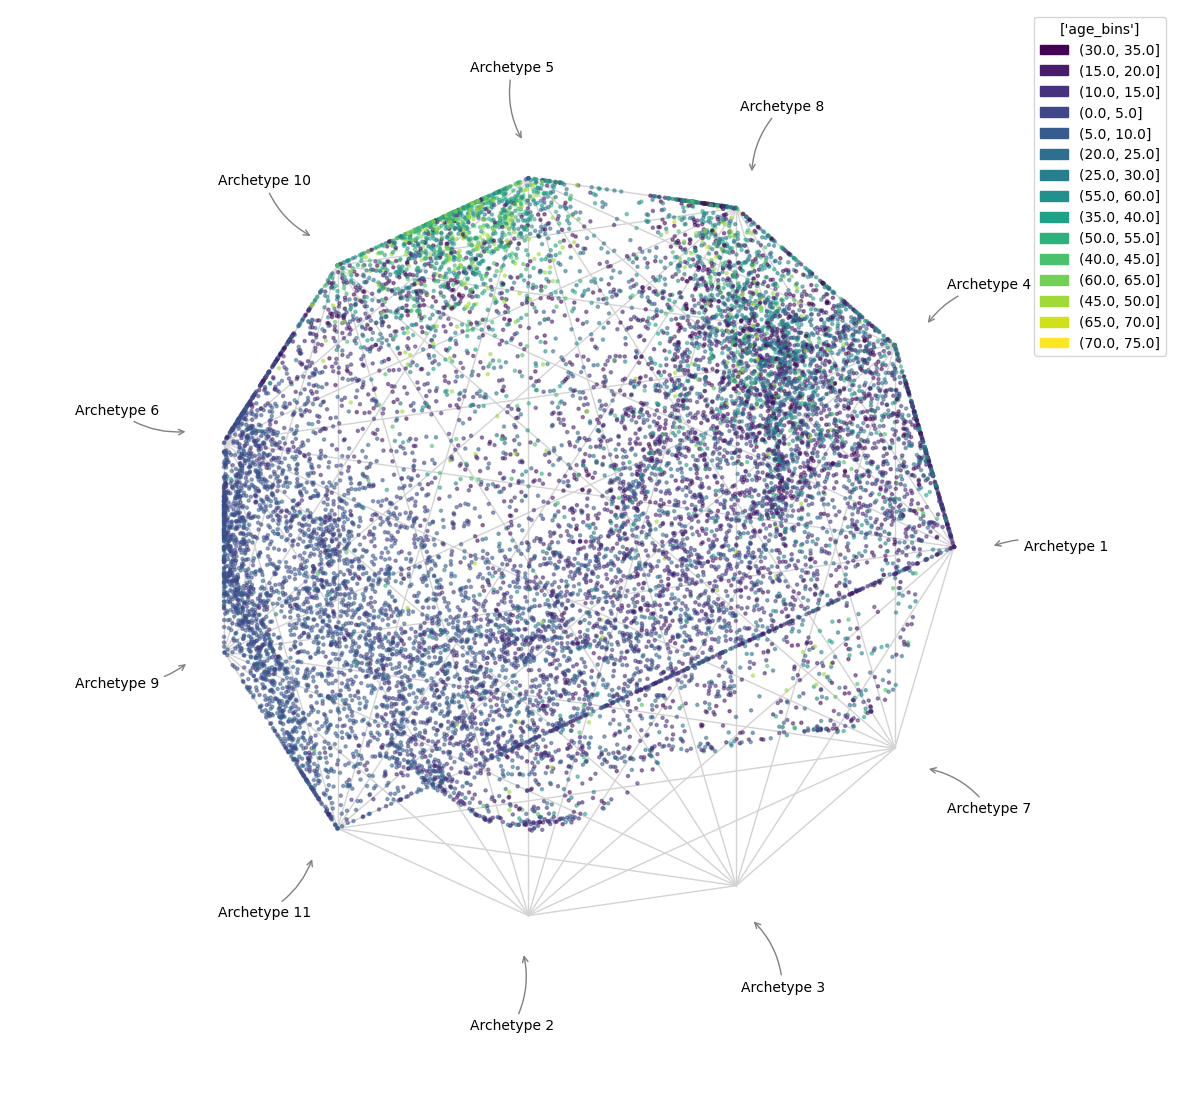

In [82]:
bin_interval = 5
# Get min, max values of the age_months column
min_age = hadza_sam["age_months"].min().round()
max_age = hadza_sam["age_months"].max().round()

# Create a binned version of the age_months column w.r.t the min and max values
bins = np.arange(min_age, max_age, bin_interval)
age_bins = pd.cut(hadza_sam["age_months"], bins=bins)

# Create a new column in the metadata DataFrame
hadza_sam["age_bins"] = age_bins

# Swapping columns
otu_aa_swapped = otu_aa[["Archetype 1", "Archetype 4", "Archetype 8", "Archetype 5", "Archetype 10","Archetype 6", "Archetype 9", "Archetype 11", "Archetype 2", "Archetype 3", "Archetype 7"]]

# Plot the data using the binned age column
plot_simplex(otu_aa_swapped, hadza_sam, ["age_bins"], "viridis", "discrete", remove_nan=True)



[4.054773724228291, 2.4580892073193334, 4.185308559219442, 20.11440462523869, 3.3009265929489353, 4.397904254886278, 8.73196305113081, 2.260667974995725, 0.8263103645006299, 2.1338257220203865]
[3, 4, 5, 6, 7, 8, 9, 10, 11, 12]


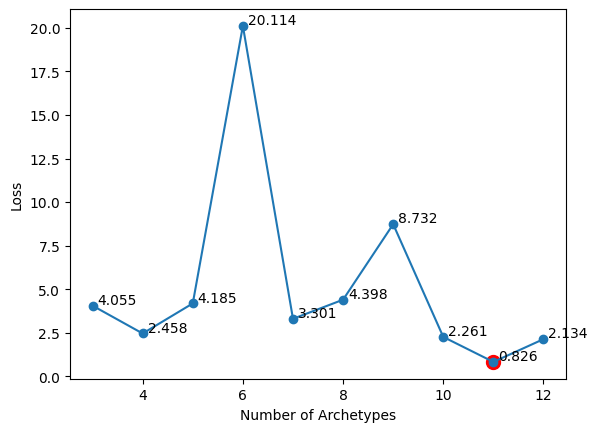

In [13]:
# Read all json files from /results/SBATCH_N3_N12, and plot the loss vs n_archetypes
import glob
import json

jsonFiles = glob.glob("results/SBATCH_N3_N12/*.json")

losses = []

for f in jsonFiles:
    aa_dict = json.load(open(f, "r"))
    losses.append(aa_dict["loss"][-1])

n_archs = [3, 4, 5, 6, 7, 8, 9, 10, 11, 12]

print(losses)
print(n_archs)

plt.plot(n_archs, losses, marker="o")
plt.xlabel("Number of Archetypes")
plt.ylabel("Loss")

# Label the losses on the plot up to 3 significant digits
pad = 0.1
for i, txt in enumerate(losses):
    plt.annotate(f"{txt:.3f}", (n_archs[i] + pad, losses[i] + pad))

# Plot the smallest loss in green
min_loss = min(losses)
min_idx = losses.index(min_loss)
plt.scatter(n_archs[min_idx], min_loss, c="red", s=100, label="Min Loss")


plt.show()



# OLD STUFF

Percentage of variance explained by the first two components: 15.20%


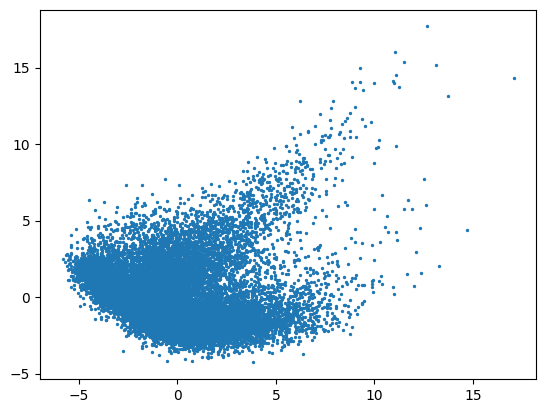

In [9]:
pca_data = otu_grouped_log # Or otu itself

pca_data = StandardScaler().fit_transform(pca_data)

pca = PCA(n_components=2)
pca.fit(pca_data)

otu_pca = pca.transform(pca_data)

variance_explained = sum(pca.explained_variance_ratio_) * 100

print(f"Percentage of variance explained by the first two components: {variance_explained:.2f}%")

plt.scatter(otu_pca[:, 0], otu_pca[:, 1], s=2)
plt.show()



In [ ]:
group = "Family" # Change this to "Kingdom", "Phylum", "Class", "Order", "Family", "Genus",to group by that taxonomic level

# No of uniques => {Kingdom: 1, Phylum: 15, Class: 25, Order: 44, Family: 77, Genus: 305}

grouped_cols = tax[group].unique()

otu_grouped = pd.DataFrame(index=otu.index, columns=grouped_cols)

i = 0
for c in tqdm(otu.columns):
    grp_col = tax[group][c]
    
    if(pd.isnull(otu_grouped[grp_col]).all()):
        otu_grouped[grp_col] = otu[c]
        continue

    otu_grouped[grp_col] = otu_grouped[grp_col] + otu[c]
    # print(f"Processed column ({i+1}/{len(otu.columns)}): {grp_col}")

    i += 1

otu_grouped.columns = otu_grouped.columns.astype(str)


100%|██████████| 3133/3133 [00:00<00:00, 4778.56it/s]


In [3]:
otu_grouped_log = otu_grouped.copy()
otu_grouped_log = otu_grouped_log.map(lambda x: np.log2(x+1))

# print(otu_grouped_log)

NameError: name 'otu_grouped' is not defined

In [38]:
!jupyter nbconvert --to python "AA_GHG_291024 copy.ipynb"

[NbConvertApp] Converting notebook AA_GHG_291024 copy.ipynb to python
[NbConvertApp] Writing 7834 bytes to AA_GHG_291024 copy.py
